# Read in the fragment files

## Files are located in:
### /group/ll001/dmakosa/projectdata/marina_snATAC/data/sNucATAC-seq_rep1/fragments.tsv.gz
### /group/ll001/dmakosa/projectdata/marina_snATAC/data/sNucATAC-seq_rep2/fragments.tsv.gz

In [4]:
import anndata as ad
import snapatac2 as snap
import numpy as np
import pandas as pd
snap.__version__

'2.6.4'

In [5]:
chromSizes = '/group/ll001/dmakosa/projectdata/marina_snATAC/lib/tair10.chromSizes.txt'
tempDir = '/group/ll001/dmakosa/tmp/'
tsvDIR = '/group/ll001/dmakosa/projectdata/marina_snATAC/tsv/'
saveDIR = '/group/ll001/dmakosa/projectdata/marina_snATAC/h5ad/'
dataDIR = '/group/ll001/dmakosa/projectdata/marina_snATAC/data/sNucATAC-seq_'

In [12]:
chromSizesDictionary = {}
with open(chromSizes) as f:
        for line in f:
            (key, value)=line.split()
            chromSizesDictionary[key]=int(value)

## Peak calling on concatenated dataset

In [6]:
fileName = 'combined'
data = snap.read(filename = (saveDIR + fileName + '_3.fragments.h5ad'), backed='r+', backend=None)

In [7]:
data

AnnData object with n_obs x n_vars = 7702 x 239339 backed at '/group/ll001/dmakosa/projectdata/marina_snATAC/h5ad/combined_3.fragments.h5ad'
    obs: 'n_fragment', 'frac_dup', 'frac_mito', '10xBC', 'Sample ID', 'mt_fraction', 'pt_fraction', 'tsse', 'log10_n_fragment', 'mask', 'Library'
    uns: 'reference_sequences', 'frag_size_distr'
    obsm: 'fragment_paired'

In [ ]:
snap.ex.export_fragments(data, groupby = 'Library', out_dir = tsvDIR, suffix = '.filtered.fragments.bed.gz') 

In [8]:
snap.tl.macs3(data, groupby='Library')

2025-07-18 12:27:08 - INFO - Exporting fragments...
2025-07-18 12:28:13 - INFO - Calling peaks...
100%|████████████████████████████████████████████████████████████████████████| 1/1 [25:50<00:00, 1550.22s/it]


In [9]:
data.uns['macs3']

{'marina': shape: (44_842, 10)
 ┌───────┬──────────┬──────────┬──────┬───┬──────────────┬─────────────┬─────────────┬──────┐
 │ chrom ┆ start    ┆ end      ┆ name ┆ … ┆ signal_value ┆ p_value     ┆ q_value     ┆ peak │
 │ ---   ┆ ---      ┆ ---      ┆ ---  ┆   ┆ ---          ┆ ---         ┆ ---         ┆ ---  │
 │ str   ┆ u64      ┆ u64      ┆ str  ┆   ┆ f64          ┆ f64         ┆ f64         ┆ u64  │
 ╞═══════╪══════════╪══════════╪══════╪═══╪══════════════╪═════════════╪═════════════╪══════╡
 │ 1     ┆ 1408     ┆ 1828     ┆ .    ┆ … ┆ 2.263966     ┆ 97.368431   ┆ 96.299751   ┆ 184  │
 │ 1     ┆ 2321     ┆ 3295     ┆ .    ┆ … ┆ 5.582214     ┆ 821.28009   ┆ 819.625793  ┆ 402  │
 │ 1     ┆ 2321     ┆ 3295     ┆ .    ┆ … ┆ 6.551544     ┆ 1127.079956 ┆ 1125.248901 ┆ 805  │
 │ 1     ┆ 3499     ┆ 3797     ┆ .    ┆ … ┆ 2.015171     ┆ 70.163513   ┆ 69.140823   ┆ 134  │
 │ 1     ┆ 6486     ┆ 6775     ┆ .    ┆ … ┆ 1.788308     ┆ 54.438839   ┆ 53.447308   ┆ 141  │
 │ …     ┆ …        ┆ …      

In [10]:
data

AnnData object with n_obs x n_vars = 7702 x 239339 backed at '/group/ll001/dmakosa/projectdata/marina_snATAC/h5ad/combined_3.fragments.h5ad'
    obs: 'n_fragment', 'frac_dup', 'frac_mito', '10xBC', 'Sample ID', 'mt_fraction', 'pt_fraction', 'tsse', 'log10_n_fragment', 'mask', 'Library'
    uns: 'macs3', 'reference_sequences', 'frag_size_distr'
    obsm: 'fragment_paired'

In [13]:
merged_peaks = snap.tl.merge_peaks(data.uns['macs3'], chrom_sizes=chromSizesDictionary)

In [14]:
merged_peaks

Peaks,marina
str,bool
"""1:1342-1843""",true
"""1:2876-3377""",true
"""1:3383-3884""",true
"""1:6377-6878""",true
"""1:8486-8987""",true
…,…
"""5:26964099-26964600""",true
"""5:26967014-26967515""",true
"""5:26969204-26969705""",true


In [15]:
peak_mat = snap.pp.make_peak_matrix(data, use_rep=merged_peaks['Peaks'], counting_strategy='paired-insertion')

/group/ll001/dmakosa/apps/miniconda3/envs/snATAC/lib/python3.12/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [16]:
peak_mat

AnnData object with n_obs × n_vars = 7702 × 36896
    obs: 'n_fragment', 'frac_dup', 'frac_mito', '10xBC', 'Sample ID', 'mt_fraction', 'pt_fraction', 'tsse', 'log10_n_fragment', 'mask', 'Library'

In [17]:
data.close()

In [18]:
peak_mat.write(filename = (saveDIR + fileName + '_4.peakMtx.h5ad'))

In [19]:
import scanpy as sc

In [42]:
data = sc.read(filename = (saveDIR + fileName + '_4.peakMtx.h5ad'))

In [43]:
data.write(filename = (saveDIR + fileName + '_4.peakMtxFeatures.h5ad'))

In [53]:
data = snap.read(filename = (saveDIR + fileName + '_4.peakMtxFeatures.h5ad'), backed='r+', backend=None)

In [54]:
snap.pp.select_features(data,
                        n_features=50000, 
                        filter_lower_quantile=0.001,
                        filter_upper_quantile=0.001,
                        whitelist=None,
                        blacklist=None,
                        max_iter=1,
                        inplace=True,
                        n_jobs=-1,
                        verbose=True)

2025-07-18 15:07:52 - INFO - Selected 36824 features.


In [55]:
snap.tl.spectral(data, 
                 n_comps=30, 
                 features='selected', 
                 random_state=27, 
                 sample_size=None, 
                 sample_method='random', 
                 chunk_size=20000, 
                 distance_metric='cosine',
                 weighted_by_sd=True,
                 feature_weights=None, 
                 inplace=True)

In [56]:
snap.pl.spectral_eigenvalues(data, width=600, height=400, show=False, interactive=True, out_file=None)

In [57]:
snap.tl.umap(data, 
             n_comps=2, 
             use_dims=None, 
             use_rep='X_spectral', 
             key_added='umap', 
             random_state=27, 
             inplace=True)

/group/ll001/dmakosa/apps/miniconda3/envs/snATAC/lib/python3.12/site-packages/umap/umap_.py:1945: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



In [58]:
snap.pp.knn(data, 
            n_neighbors=50, 
            use_dims=None, 
            use_rep='X_spectral', 
            method='kdtree', 
            inplace=True, 
            random_state=27)

In [59]:
snap.tl.leiden(data, 
               resolution=1, 
               objective_function='modularity', 
               min_cluster_size=5, 
               n_iterations=-1, 
               random_state=27, 
               key_added='leiden', 
               use_leidenalg=False, 
               weighted=False, 
               inplace=True)

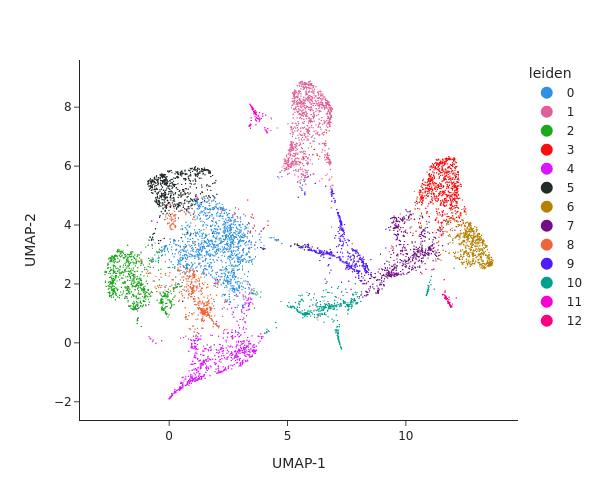

In [60]:
snap.pl.umap(data, color='leiden', interactive=False, height=500)

In [61]:
data.close()